# Days 8-9: Two-tower model
Popularity gives everyone the same list, and ALS only knows IDs. A **two-tower model** builds a customer vector from customer features and an article vector from article features; the score is their dot product. Day 8 builds the data and the towers, Day 9 trains them.

**Checks:** each check prints what I got next to what I expected (no asserts). If they differ, stop and find out why.

**Framework: Keras.** I already know Keras, and the two-tower model is the hardest part of this project, so I learn one hard thing at a time: the model, not a new framework too. What I give up: the in-batch loss needs my own `train_step`, because standard `model.fit` losses expect one label per row.

## Names used in this notebook
| Name | What it is |
|---|---|
| `train`, `val` | purchase tables (weeks 0-9, week 10) |
| `customer_vocab`, `article_vocab`, ... | Day 5 mappings: value -> number (1..N, 0 = unknown) |
| `build_customer_features(ids)` | any customers -> their indexed features (ONE function for training and evaluation) |
| `customer_table`, `article_table` | one row per train customer / article, all numbers |
| `pairs` | one row per train purchase (2,638,103), every feature as a number |
| `dataset` | `pairs` as shuffled batches of 1,024 |
| `build_tower(...)` | builds a tower: features in -> 64 numbers of length 1 out |
| `user_keys`, `item_keys` | which batch columns go to which tower |
| `false_negative_mask(ids)` | True where two rows of a batch bought the same article |
| `log_q_table` | log of each article's share of training rows (logQ correction) |
| `in_batch_loss(...)` | the loss: each row of the score grid is a 1,024-way multiple choice |
| `TwoTowerModel` | both towers + my own `train_step` |
| `evaluate_two_tower(...)` | recall@10 / NDCG@10 on all 72,019 validation customers |
| `RecallCallback` | runs the evaluation after every epoch |

In [1]:
import json
import math
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers

print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


# Day 8
## Step 3: Dot product vs cosine (on paper)
Customer **u = [3, 0, 4]**, article **a = [1, 0, 0]**, article **b = [6, 0, 8]** (same direction as u, twice as long).

| | Value |
|---|---|
| Lengths (square root of the sum of squares) | \|u\| = √25 = **5**, \|a\| = **1**, \|b\| = √100 = **10** |
| Dot products | u·a = **3**, u·b = 18 + 32 = **50** |
| Cosines = dot ÷ (length × length) | cos(u, a) = 3 ÷ 5 = **0.6**, cos(u, b) = 50 ÷ 50 = **1.0** |

b scores 50 partly because it is **long**. Popular articles tend to get longer vectors, so the plain dot product quietly favours them: the Day 2 popularity bias again.

**Why normalise the tower outputs:** dividing each vector by its length makes every vector length 1, so the dot product becomes the cosine and the model scores by **direction** (taste), not size (popularity).

In [2]:
u = np.array([3, 0, 4])
a = np.array([1, 0, 0])
b = np.array([6, 0, 8])

print('Lengths:', np.linalg.norm(u), np.linalg.norm(a), np.linalg.norm(b), '| expected 5 1 10')
print('Dot products:', u @ a, u @ b, '| expected 3 50')
print('Cosines:', (u @ a) / (np.linalg.norm(u) * np.linalg.norm(a)),
      (u @ b) / (np.linalg.norm(u) * np.linalg.norm(b)), '| expected 0.6 1.0')

# After dividing by the length, the dot product IS the cosine
print('Normalised u·b:', (u / np.linalg.norm(u)) @ (b / np.linalg.norm(b)), '| expected 1.0')

Lengths: 5.0 1.0 10.0 | expected 5 1 10
Dot products: 3 50 | expected 3 50
Cosines: 0.6 1.0 | expected 0.6 1.0
Normalised u·b: 1.0 | expected 1.0


## Step 4: Load the data and the Day 5 features
The network only sees numbers from these mappings. If one loads wrong (the JSON trap: number keys turned into text), training runs without errors and just gives bad numbers, so every size is checked against Day 5.

In [3]:
FEATURES_FOLDER = '../data/processed/features'

train = pd.read_parquet('../data/processed/train.parquet')
val = pd.read_parquet('../data/processed/val.parquet')
customers = pd.read_parquet('../data/RAW/customers.parquet')
customers_idx = pd.read_parquet('../data/processed/customer_join_idx.parquet')
articles = pd.read_parquet('../data/RAW/articles.parquet')

print('Train rows:', len(train), '| expected 2,638,103')
print('Val rows:  ', len(val), '| expected 230,980')

Train rows: 2638103 | expected 2,638,103
Val rows:   230980 | expected 230,980


In [4]:
def load_vocab(name):
    # Day 5 mapping as a dict: value -> number (1..N, 0 = unknown)
    table = pd.read_parquet(FEATURES_FOLDER + '/vocab_' + name + '.parquet')
    return dict(zip(table['value'], table['index']))

customer_vocab = load_vocab('customer')
article_vocab = load_vocab('article')
age_bucket_vocab = load_vocab('age_bucket')
club_member_status_vocab = load_vocab('club_member_status')
fashion_news_frequency_vocab = load_vocab('fashion_news_frequency')

print('Customers:  ', len(customer_vocab), '| expected 444,431')
print('Articles:   ', len(article_vocab), '| expected 38,603')
print('Age buckets:', len(age_bucket_vocab), '| expected 7')
print('Club status:', club_member_status_vocab)
print('News freq:  ', fashion_news_frequency_vocab)

# The JSON trap: keys must still be numbers, not text
first_article = list(article_vocab.keys())[0]
print('Article key:', first_article, type(first_article), '| expected a number, not str')

Customers:   444431 | expected 444,431
Articles:    38603 | expected 38,603
Age buckets: 7 | expected 7
Club status: {'ACTIVE': 1, 'LEFT CLUB': 2, 'PRE-CREATE': 3}
News freq:   {'Monthly': 1, 'NONE': 2, 'Regularly': 3}
Article key: 108775015 <class 'int'> | expected a number, not str


In [5]:
# Age edges were saved on Day 5: load them, never retype them
with open(FEATURES_FOLDER + '/settings.json') as f:
    feature_settings = json.load(f)
age_edges = feature_settings['age_edges']
print('Age edges:', age_edges, '| expected [16, 20, 25, 30, 40, 50, 60, 100]')

article_price = pd.read_parquet(FEATURES_FOLDER + '/article_median_price.parquet')
print('Article prices:', len(article_price), '| expected 38,603')

Age edges: [16, 20, 25, 30, 40, 50, 60, 100] | expected [16, 20, 25, 30, 40, 50, 60, 100]
Article prices: 38603 | expected 38,603


## Step 5a: Customer features, as ONE function
The same function builds the features for **training** customers and for **validation** customers (including cold ones). Two separate pieces of code could drift apart (a missing None -> NONE fix, a different age edge) and feed the model inputs it never saw in training, with no error. That's **training-serving skew**. One function, used everywhere, makes it impossible. (Day 9 Step 8 first proved, with a parity test, that this function gives exactly the table my original Day 8 cells built; now training uses it directly.)

In [6]:
# The raw customers file with the customer_join_idx key added. Done ONCE (1.37M rows), not inside the function
customers_with_idx = customers.merge(customers_idx, on='customer_id', how='inner', validate='one_to_one')
print('Customers with key:', len(customers_with_idx), '| expected 1,371,980')

Customers with key: 1371980 | expected 1,371,980


In [7]:
def build_customer_features(customer_join_ids):
    # Any list of customers -> one row each, every feature as a vocabulary number.
    # Customers not in the training vocabulary (cold) get customer_idx 0 = unknown.
    table = customers_with_idx[customers_with_idx['customer_join_idx'].isin(customer_join_ids)].copy()

    # FN / Active: missing means "no" (Day 5 decision)
    table['FN'] = table['FN'].fillna(0)
    table['Active'] = table['Active'].fillna(0)

    # News frequency: spelling fix FIRST, then the vocabulary, missing -> 0
    table['fashion_news_frequency'] = table['fashion_news_frequency'].replace('None', 'NONE')
    table['fashion_news_frequency'] = table['fashion_news_frequency'].map(fashion_news_frequency_vocab).fillna(0)

    table['club_member_status'] = table['club_member_status'].map(club_member_status_vocab).fillna(0)

    # Age -> bucket labelled by its left edge (20 goes into [20, 25)) -> vocabulary number
    table['age'] = pd.cut(table['age'], bins=age_edges, right=False, labels=age_edges[:-1]).astype('float')
    table['age'] = table['age'].map(age_bucket_vocab).fillna(0)

    table['customer_idx'] = table['customer_join_idx'].map(customer_vocab).fillna(0)   # cold -> 0

    # These columns now hold NUMBERS, not raw values: the names say so
    # (otherwise someone at serving time passes age=34 into an embedding with 8 rows)
    table = table.rename(columns={
        'age': 'age_bucket_idx',
        'club_member_status': 'club_member_status_idx',
        'fashion_news_frequency': 'fashion_news_frequency_idx',
    })
    return table[['customer_join_idx', 'customer_idx', 'age_bucket_idx', 'club_member_status_idx',
                  'fashion_news_frequency_idx', 'FN', 'Active']]

In [8]:
customer_table = build_customer_features(train['customer_join_idx'].unique())

print('Train customers:', len(customer_table), '| expected 444,431')
print('Missing values: ', customer_table.isna().sum().sum(), '| expected 0')
print('Smallest customer_idx:', customer_table['customer_idx'].min(), '| expected 1 (every train customer is known)')
customer_table.head()

Train customers: 444431 | expected 444,431
Missing values:  0 | expected 0
Smallest customer_idx: 1 | expected 1 (every train customer is known)


,customer_join_idx,customer_idx,age_bucket_idx,club_member_status_idx,fashion_news_frequency_idx,FN,Active
0,0,1,5.0,1.0,2.0,0.0,0.0
1,1,2,3.0,1.0,2.0,0.0,0.0
4,4,3,6.0,1.0,3.0,1.0,1.0
10,10,4,3.0,1.0,2.0,0.0,0.0
13,13,5,6.0,1.0,3.0,1.0,1.0


## Step 5b: Article features and price
**Price:** H&M prices are tiny (about 0.0008 to 0.51). For tiny x, `log1p(x) ≈ x`, so log1p did nothing and the max was still 17.8 standard deviations out. Plain `np.log` squashes ratios (every 10x price adds the same amount). log(0) = -infinity, so first check every price is above 0. Mean and std are taken across the **38,603 articles**, not the 2.6M rows, so bestsellers don't drag the mean, and they are **saved**, because serving must scale prices exactly the same way.

In [9]:
article_table = articles[articles['article_id'].isin(train['article_id'].unique())].copy()
print('Train articles:', len(article_table), '| expected 38,603')

article_table['article_idx'] = article_table['article_id'].map(article_vocab)

article_columns = ['product_code', 'product_type_no', 'product_group_name', 'graphical_appearance_name',
                   'colour_group_name', 'perceived_colour_master_name', 'department_no',
                   'index_group_name', 'section_name', 'garment_group_name']
for name in article_columns:
    vocab = load_vocab(name)
    article_table[name + '_idx'] = article_table[name].map(vocab).fillna(0)

Train articles: 38603 | expected 38,603


In [10]:
article_table = article_table.merge(article_price, on='article_id', how='left', validate='one_to_one')
print('Smallest median price:', article_table['median_price'].min(), '| expected above 0 (about 0.0008)')

article_table['price_log'] = np.log(article_table['median_price'])
price_log_mean = article_table['price_log'].mean()
price_log_std = article_table['price_log'].std()
article_table['price_scaled'] = (article_table['price_log'] - price_log_mean) / price_log_std

print('Log mean / std:', round(price_log_mean, 4), '/', round(price_log_std, 4), '| expected -3.9165 / 0.7523')
print('Scaled min / max:', round(article_table['price_scaled'].min(), 2), '/',
      round(article_table['price_scaled'].max(), 2), '| expected about -4.28 / 4.30 (17.8 with log1p)')

with open(FEATURES_FOLDER + '/price_scaling.json', 'w') as f:
    json.dump({'price_log_mean': float(price_log_mean), 'price_log_std': float(price_log_std),
               'transform': 'log'}, f, indent=4)

article_table = article_table[['article_id', 'article_idx'] + [name + '_idx' for name in article_columns]
                              + ['price_scaled']].copy()
print('Missing values:', article_table.isna().sum().sum(), '| expected 0')

Smallest median price: 0.0007966102 | expected above 0 (about 0.0008)
Log mean / std: -3.9165 / 0.7523 | expected -3.9165 / 0.7523
Scaled min / max: -4.28 / 4.3 | expected about -4.28 / 4.30 (17.8 with log1p)
Missing values: 0 | expected 0


## Step 5c: The training pairs table
**One row per purchase (2,638,103), not per unique pair.** Day 8 Step 1 showed repeats are the strongest signal; an article bought on 3 different days appears 3 times, so the model learns that repeats matter (the same idea as ALS's confidence weights).

Small tables first (one row per customer / article), merged last. `validate='many_to_one'` makes pandas raise an error if a key is duplicated on the right side, instead of silently doubling rows.

In [11]:
pairs = train[['customer_join_idx', 'article_id']]
pairs = pairs.merge(customer_table, on='customer_join_idx', how='left', validate='many_to_one')
print('After customer merge:', len(pairs), '| expected 2,638,103')
pairs = pairs.merge(article_table, on='article_id', how='left', validate='many_to_one')
print('After article merge: ', len(pairs), '| expected 2,638,103')

pairs = pairs.drop(columns=['customer_join_idx', 'article_id'])
for name in pairs.columns:
    if name in ['FN', 'Active', 'price_scaled']:
        pairs[name] = pairs[name].astype('float32')
    else:
        pairs[name] = pairs[name].astype('int32')

After customer merge: 2638103 | expected 2,638,103
After article merge:  2638103 | expected 2,638,103


## Step 6: Check the pairs table
A neural network almost never fails loudly on bad inputs, it just trains to a worse number. Every index must be at least 1 for customer and article (every train customer and article is known), and no index may be bigger than its vocabulary (the embedding has vocabulary + 1 rows).

In [12]:
print('Rows:', len(pairs), '| expected 2,638,103')
print('Missing values:', pairs.isna().sum().sum(), '| expected 0')
print('Smallest customer / article index:', pairs['customer_idx'].min(), pairs['article_idx'].min(), '| expected 1 1')
print()
print('Largest value per column:')
print(pairs.max())

Rows: 2638103 | expected 2,638,103
Missing values: 0 | expected 0
Smallest customer / article index: 1 1 | expected 1 1

Largest value per column:
customer_idx                        444431.000000
age_bucket_idx                           7.000000
club_member_status_idx                   3.000000
fashion_news_frequency_idx               3.000000
FN                                       1.000000
Active                                   1.000000
article_idx                          38603.000000
product_code_idx                     19354.000000
product_type_no_idx                    123.000000
product_group_name_idx                  18.000000
graphical_appearance_name_idx           30.000000
colour_group_name_idx                   50.000000
perceived_colour_master_name_idx        20.000000
department_no_idx                      286.000000
index_group_name_idx                     5.000000
section_name_idx                        56.000000
garment_group_name_idx                  21.000000
pri

## Step 7: Batches with tf.data
Keras trains from a dataset that hands it one batch at a time: a dictionary, column name -> 1,024 values.

**Why shuffle twice:** train is in date order, so an unshuffled batch is one day's shoppers buying that day's bestsellers, and the in-batch negatives (Day 9) would be the same few articles. A 100,000-row buffer only mixes about 4 days, so I shuffle the whole table once with pandas first; the buffer then reshuffles each epoch. **drop_remainder=True** keeps every batch exactly 1,024 rows, so every score grid is 1,024 x 1,024 (2,576 batches, 279 rows dropped).

In [13]:
pairs = pairs.sample(frac=1, random_state=42).reset_index(drop=True)   # full shuffle, once

features = {}
for name in pairs.columns:
    features[name] = pairs[name].to_numpy()

dataset = tf.data.Dataset.from_tensor_slices(features)   # cut into rows
dataset = dataset.shuffle(100000, seed=42)                # reshuffle every epoch
dataset = dataset.batch(1024, drop_remainder=True)        # 1,024 rows per batch
dataset = dataset.prefetch(tf.data.AUTOTUNE)              # prepare the next batch while training

for batch in dataset.take(1):
    for name in batch:
        print(name, batch[name].shape, batch[name].dtype)

customer_idx (1024,) <dtype: 'int32'>
age_bucket_idx (1024,) <dtype: 'int32'>
club_member_status_idx (1024,) <dtype: 'int32'>
fashion_news_frequency_idx (1024,) <dtype: 'int32'>
FN (1024,) <dtype: 'float32'>
Active (1024,) <dtype: 'float32'>
article_idx (1024,) <dtype: 'int32'>
product_code_idx (1024,) <dtype: 'int32'>
product_type_no_idx (1024,) <dtype: 'int32'>
product_group_name_idx (1024,) <dtype: 'int32'>
graphical_appearance_name_idx (1024,) <dtype: 'int32'>
colour_group_name_idx (1024,) <dtype: 'int32'>
perceived_colour_master_name_idx (1024,) <dtype: 'int32'>
department_no_idx (1024,) <dtype: 'int32'>
index_group_name_idx (1024,) <dtype: 'int32'>
section_name_idx (1024,) <dtype: 'int32'>
garment_group_name_idx (1024,) <dtype: 'int32'>
price_scaled (1024,) <dtype: 'float32'>


## Steps 8-9: The towers
A tower turns one customer's (or article's) features into 64 numbers of length 1. One function builds both towers, so the second tower is just a different feature list.

| Layer | Why |
|---|---|
| `keras.Input(shape=(), name=...)` | an empty slot per feature; the name must match the batch key exactly |
| `Embedding(vocab + 1, size)` | a lookup table: index -> a learned vector (+1 because row 0 = unknown) |
| `Reshape((1,))` for plain numbers | (batch,) -> (batch, 1) so it can be glued next to the embeddings |
| `Concatenate` | glue everything into one row |
| `Dense(128, relu, he_normal)` | mixes features; He init starts weights a bit larger because ReLU zeroes about half the values |
| `Dropout(0.2)` | switches off 20% during training only: the median customer has 4 purchases, easy to memorise |
| `Dense(64)`, **no activation** | the vector; ReLU would make every value >= 0 and cosine could never be negative |
| `UnitNormalization()` | length 1, so dot product = cosine (Step 3) |

**Embedding sizes:** up to ~10 values -> 4, tens -> 8, hundreds -> 16, tens of thousands -> 32. A big vector for a rare value only memorises noise.

**Both towers output exactly 64:** the score is a dot product, which pairs position i of the user vector with position i of the item vector.

In [14]:
def build_tower(categorical, numeric, tower_name, dropout=0.2):
    # categorical: {name: (input_dim, output_dim)}, numeric: [names of plain number columns]
    inputs = {}
    pieces = []

    for name in categorical:                      # categories: empty slot -> lookup table
        input_dim, output_dim = categorical[name]
        inputs[name] = keras.Input(shape=(), dtype='int32', name=name)
        pieces.append(layers.Embedding(input_dim, output_dim, name=name + '_embedding')(inputs[name]))

    for name in numeric:                          # numbers: empty slot -> (batch, 1)
        inputs[name] = keras.Input(shape=(), dtype='float32', name=name)
        pieces.append(layers.Reshape((1,), name=name + '_reshape')(inputs[name]))

    x = layers.Concatenate(name=tower_name + '_concat')(pieces)
    x = layers.Dense(128, activation='relu', kernel_initializer='he_normal', name=tower_name + '_dense_1')(x)
    x = layers.Dropout(dropout, name=tower_name + '_dropout')(x)
    x = layers.Dense(64, name=tower_name + '_dense_out')(x)
    vector = layers.UnitNormalization(name=tower_name + '_normalise')(x)

    return keras.Model(inputs=inputs, outputs=vector, name=tower_name)

In [15]:
# name: (vocabulary size + 1, embedding size). Sizes come from the saved vocabularies, never typed
user_categorical = {
    'customer_idx':               (len(customer_vocab) + 1, 32),
    'age_bucket_idx':             (len(age_bucket_vocab) + 1, 4),
    'club_member_status_idx':     (len(club_member_status_vocab) + 1, 4),
    'fashion_news_frequency_idx': (len(fashion_news_frequency_vocab) + 1, 4),
}
user_numeric = ['FN', 'Active']

item_categorical = {
    'article_idx':                      (len(article_vocab) + 1, 32),
    'product_code_idx':                 (len(load_vocab('product_code')) + 1, 32),
    'product_type_no_idx':              (len(load_vocab('product_type_no')) + 1, 16),
    'department_no_idx':                (len(load_vocab('department_no')) + 1, 16),
    'product_group_name_idx':           (len(load_vocab('product_group_name')) + 1, 8),
    'graphical_appearance_name_idx':    (len(load_vocab('graphical_appearance_name')) + 1, 8),
    'colour_group_name_idx':            (len(load_vocab('colour_group_name')) + 1, 8),
    'perceived_colour_master_name_idx': (len(load_vocab('perceived_colour_master_name')) + 1, 8),
    'section_name_idx':                 (len(load_vocab('section_name')) + 1, 8),
    'garment_group_name_idx':           (len(load_vocab('garment_group_name')) + 1, 8),
    'index_group_name_idx':             (len(load_vocab('index_group_name')) + 1, 4),
}
item_numeric = ['price_scaled']

# Which batch columns go to which tower
user_keys = list(user_categorical.keys()) + user_numeric
item_keys = list(item_categorical.keys()) + item_numeric
print('User keys:', len(user_keys), '| item keys:', len(item_keys), '| expected 6 and 12')
print('Every batch column used exactly once?', len(user_keys) + len(item_keys) == len(features), '| expected True')

User keys: 6 | item keys: 12 | expected 6 and 12
Every batch column used exactly once? True | expected True


In [16]:
user_tower = build_tower(user_categorical, user_numeric, 'user_tower')
item_tower = build_tower(item_categorical, item_numeric, 'item_tower')
item_tower.summary()

Model: "item_tower"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ article_idx         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_code_idx    │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_type_no_idx │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ department_no_idx   │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_group_name… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graphical_appearan… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ colour_group_name_… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ perceived_colour_m… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ section_name_idx    │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ garment_group_name… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ index_group_name_i… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ price_scaled        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ article_idx_embedd… │ (None, 32)        │  1,235,328 │ article_idx[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_code_idx_e… │ (None, 32)        │    619,360 │ product_code_idx… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_type_no_id… │ (None, 16)        │      1,984 │ product_type_no_… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ department_no_idx_… │ (None, 16)        │      4,592 │ department_no_id… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_group_name… │ (None, 8)         │        152 │ product_group_na

 Total params: 1,890,352 (7.21 MB)

 Trainable params: 1,890,352 (7.21 MB)

 Non-trainable params: 0 (0.00 B)

## Step 10: Parameter counts
**Predicted:** customer embedding = 444,432 x 32 = **14,221,824**; article embedding = 38,604 x 32 = **1,235,328**.

1. Almost all parameters live in the ID embeddings (99.9% of the user tower, 65% of the item tower); the dense layers are under 2% of the model.
2. Each customer gets 32 numbers from a median of only 4 training rows: **more knobs than evidence**, so the customer table can memorise instead of learning taste. Dropout pushes the dense layers to lean on shared features (age, club status), and cold customers (ID row 0) depend entirely on those shared features.
3. Serving the user tower means loading the 14.2M-number table: about 57 MB as float32 (note for the Day 11 memory check).

In [17]:
user_total = user_tower.count_params()
item_total = item_tower.count_params()
print('User tower:', format(user_total, ','), '| customer embedding', format(444432 * 32, ','),
      '=', round(444432 * 32 / user_total * 100, 1), '%')
print('Item tower:', format(item_total, ','), '| article embedding ', format(38604 * 32, ','),
      '=', round(38604 * 32 / item_total * 100, 1), '%')
print('Both towers:', format(user_total + item_total, ','), '| expected 16,126,512')

User tower: 14,236,160 | customer embedding 14,221,824 = 99.9 %
Item tower: 1,890,352 | article embedding  1,235,328 = 65.3 %
Both towers: 16,126,512 | expected 16,126,512


## Step 11: One batch through both towers
Each tower gets only its own keys, with `training=False` (Dropout off, so the check is repeatable). In the 1,024 x 1,024 score grid, the **diagonal** is each customer's score for the article they actually bought; every other cell in the row is another customer's article (an in-batch negative). Untrained, the diagonal is no better than the rest.

In [18]:
def split_batch(batch):
    # One batch dictionary -> (the user tower's columns, the item tower's columns)
    user_inputs = {}
    for name in user_keys:
        user_inputs[name] = batch[name]
    item_inputs = {}
    for name in item_keys:
        item_inputs[name] = batch[name]
    return user_inputs, item_inputs

for batch in dataset.take(1):
    user_inputs, item_inputs = split_batch(batch)

user_vectors = user_tower(user_inputs, training=False).numpy()
item_vectors = item_tower(item_inputs, training=False).numpy()
print('Vectors:', user_vectors.shape, item_vectors.shape, '| expected (1024, 64) (1024, 64)')

lengths = np.linalg.norm(user_vectors, axis=1)       # one length per row
print('User vector lengths:', round(lengths.min(), 5), 'to', round(lengths.max(), 5), '| expected 1 to 1')

scores = user_vectors @ item_vectors.T
diagonal = np.diag(scores)
print('Score grid:', scores.shape, '| range', round(scores.min(), 3), 'to', round(scores.max(), 3), '| expected inside -1..1')
print('Diagonal average:', round(diagonal.mean(), 4), '| rest:', round((scores.sum() - diagonal.sum()) / (1024 * 1024 - 1024), 4),
      '| expected about equal (untrained)')

Vectors: (1024, 64) (1024, 64) | expected (1024, 64) (1024, 64)
User vector lengths: 1.0 to 1.0 | expected 1 to 1
Score grid: (1024, 1024) | range -0.481 to 0.438 | expected inside -1..1
Diagonal average: -0.0317 | rest: -0.0311 | expected about equal (untrained)


# Day 9: Teaching the model with in-batch softmax
Each row of the score grid is a multiple-choice question: "which of these 1,024 articles did this customer buy?" The right answer is the diagonal. The loss rewards the model when the diagonal wins its row.

## Step 1: In-batch softmax on paper

| | Article 1 | Article 2 | Article 3 |
|---|---|---|---|
| Customer 1 | **0.8** | 0.1 | 0.0 |
| Customer 2 | 0.3 | **0.5** | 0.2 |
| Customer 3 | 0.6 | 0.4 | **0.1** |

One row: e^score for each cell -> divide by the row total (softmax) -> loss = −log(softmax of the diagonal).

| Row | Temperature 1: softmax | Loss | Temperature 0.1: softmax | Loss |
|---|---|---|---|---|
| 1 | **0.5139**, 0.2552, 0.2309 | 0.6657 | **0.9988**, 0.0009, 0.0003 | 0.0012 |
| 2 | 0.3199, **0.3907**, 0.2894 | 0.9398 | 0.1142, **0.8438**, 0.0420 | 0.1698 |
| 3 | 0.4123, 0.3376, **0.2501** | 1.3859 | 0.8756, 0.1185, **0.0059** | 5.1328 |
| **Average** | | **0.9972** | | **1.7680** |

- **Row 3 is the model being wrong** (0.6 beats the real purchase 0.1): the largest loss both times, so training works hardest there.
- **Temperature:** cosine only spans −1 to 1, too narrow for the softmax to become confident (row 1 is clearly right but only reaches 0.51). Dividing by a small temperature stretches the scores until a right answer can win clearly (0.9988) and a wrong one is punished hard (1.39 -> 5.13). That is also why the 0.1 average is higher: sharper in both directions.

In [19]:
grid = [[0.8, 0.1, 0.0],
        [0.3, 0.5, 0.2],
        [0.6, 0.4, 0.1]]

for temperature in [1, 0.1]:
    row_losses = []
    for i in range(3):
        exps = []
        for score in grid[i]:
            exps.append(math.exp(score / temperature))
        softmax = []
        for value in exps:
            softmax.append(value / sum(exps))
        row_losses.append(-math.log(softmax[i]))          # the diagonal is column i
    print('T =', temperature, '| row losses', [round(x, 4) for x in row_losses], '| average', round(sum(row_losses) / 3, 4))
print('Expected averages: 0.9972 (T = 1) and 1.768 (T = 0.1)')

T = 1 | row losses [0.6657, 0.9398, 1.3859] | average 0.9972
T = 0.1 | row losses [0.0012, 0.1698, 5.1328] | average 1.768
Expected averages: 0.9972 (T = 1) and 1.768 (T = 0.1)


## Step 2: The gradient is "predicted minus true"
**gradient for each cell = softmax − (1 if diagonal, else 0).** Row 1 at temperature 1: 0.5139 − 1 = **−0.4861** (the score goes up, because gradient descent moves against the gradient), **0.2552** and **0.2309** (pushed down). They add up to 0: what the right answer gains, the negatives lose. TensorFlow's GradientTape must give the same numbers; tomorrow's `train_step` uses the same tool on 16 million weights.

In [20]:
row1 = tf.Variable([[0.8, 0.1, 0.0]])        # one row, three articles
label = tf.constant([0])                    # the right answer is column 0

with tf.GradientTape() as tape:             # records every calculation inside
    loss = keras.losses.sparse_categorical_crossentropy(label, row1, from_logits=True)
gradient = tape.gradient(loss, row1)

print('Loss:    ', round(float(loss[0]), 4), '| expected 0.6657')
print('Gradient:', gradient.numpy().round(4), '| expected [[-0.4861  0.2552  0.2309]]')

Loss:     0.6657 | expected 0.6657
Gradient: [[-0.4861  0.2552  0.2309]] | expected [[-0.4861  0.2552  0.2309]]


## Step 4: Duplicates in a batch (false negatives)
If rows 5 and 9 both bought article A, then in row 5, column 9 is also article A, but the loss treats it as a negative. The loss pushes A up and down at the same time for the same customer. **Measure first:** the top article alone (3,853 of 2,638,103 rows) is expected 3,853 / 2,638,103 x 1,024 ≈ **1.5 times per batch**, so duplicates can't be rare.

In [21]:
top_count = pairs['article_idx'].value_counts().max()
total_rows = len(pairs)
print('Top article per batch, predicted:', round(top_count / total_rows * 1024, 2))

duplicate_counts = []
for batch in dataset.take(50):
    article_ids = batch['article_idx'].numpy()
    duplicate_counts.append(1024 - len(np.unique(article_ids)))

# report ONCE, after the loop
print('Duplicates per batch (50 batches):', round(np.mean(duplicate_counts), 1),
      '=', round(np.mean(duplicate_counts) / 1024 * 100, 1), '% of rows')

Top article per batch, predicted: 1.5
Duplicates per batch (50 batches): 83.1 = 8.1 % of rows


**The mask:** compare the batch's article ids as a column against a row -> a True/False grid (True = same article). Switch the diagonal off (those are the real answers). Wherever it's still True, the score becomes −1e9, which turns into 0 after exp, so the cell drops out of the row. Not −infinity: a fully masked row would give 0 ÷ 0 = NaN.

In [22]:
def false_negative_mask(article_ids):
    same_article = tf.equal(tf.expand_dims(article_ids, 1),      # column (n, 1)
                            tf.expand_dims(article_ids, 0))      # row    (1, n)  -> grid (n, n)
    diagonal = tf.eye(tf.shape(article_ids)[0], dtype=tf.bool)
    return tf.logical_and(same_article, tf.logical_not(diagonal))

# Toy test: rows 0 and 2 bought article 7 -> only cells (0, 2) and (2, 0)
print(false_negative_mask(tf.constant([7, 4, 7])).numpy())
print('expected [[F F T] [F F F] [T F F]]')
print('No duplicates [1, 2, 3], any True?', bool(tf.reduce_any(false_negative_mask(tf.constant([1, 2, 3])))), '| expected False')

[[False False  True]
 [False False False]
 [ True False False]]
expected [[F F T] [F F F] [T F F]]
No duplicates [1, 2, 3], any True? False | expected False


## Step 5: The logQ correction
Negatives come from other rows, and rows are mostly popular articles, so a bestseller is pushed down in almost every batch: for **showing up a lot**, not for being disliked. Subtracting log q(j) (article j's share of training rows) from column j cancels that sampling bias (Yi et al., 2019).

| Article | q | log q | added to its column |
|---|---|---|---|
| bestseller (3,853 rows) | 0.00146 | **−6.53** | +6.53 |
| bought once | 0.00000038 | **−14.79** | +14.79 |

**Training only, never at serving:** logQ corrects how training *samples negatives*. Serving scores every article with the plain dot product, so adding it there would be train-serve skew.

In [23]:
# Rows per article index. minlength: the array covers every index 0..38,603, even ones that never appear
article_counts = np.bincount(pairs['article_idx'], minlength=len(article_vocab) + 1)
q = article_counts / total_rows
q[0] = 1 / total_rows               # index 0 never appears in training; log(0) would be -infinity
log_q_table = tf.constant(np.log(q), dtype=tf.float32)

print('Counted rows:', article_counts.sum(), '| expected 2,638,103')
print('Top article log q:', round(float(log_q_table[np.argmax(article_counts)]), 3), '| expected -6.529')
print('Bought-once log q:', round(float(log_q_table[np.where(article_counts == 1)[0][0]]), 3), '| expected -14.786')
print('Table min / max:', round(float(tf.reduce_min(log_q_table)), 2), '/', round(float(tf.reduce_max(log_q_table)), 2), '| no -inf')

Counted rows: 2638103 | expected 2,638,103
Top article log q: -6.529 | expected -6.529
Bought-once log q: -14.786 | expected -14.786
Table min / max: -14.79 / -6.53 | no -inf


## Step 3 (final version): in_batch_loss
1. divide the grid by the temperature
2. subtract log q, as a (1, N) row, so every row loses the same amount per column
3. mask the duplicates with −1e9 (last, so masked cells are exactly −1e9)
4. labels 0, 1, ..., batch − 1 (row i's answer is column i) -> cross-entropy from logits -> mean

`article_ids` and `log_q_table` are optional (`None`), so the old calls still work: that's what the regression tests check.

In [24]:
def in_batch_loss(scores, temperature, article_ids=None, log_q_table=None):
    scores = scores / temperature                                         # 1.

    if article_ids is not None and log_q_table is not None:
        batch_log_q = tf.reshape(tf.gather(log_q_table, article_ids), (1, -1))
        scores = scores - batch_log_q                                     # 2.
        scores = tf.where(false_negative_mask(article_ids),
                          tf.cast(-1e9, scores.dtype), scores)            # 3.

    labels = tf.range(tf.shape(scores)[0])                                # 4.
    row_losses = keras.losses.sparse_categorical_crossentropy(labels, scores, from_logits=True)
    return tf.reduce_mean(row_losses)

In [25]:
paper_grid = tf.constant(grid)

# Regression test 1: the old call
print('Paper grid T = 1:  ', round(float(in_batch_loss(paper_grid, 1.0)), 4), '| expected 0.9972')
print('Paper grid T = 0.1:', round(float(in_batch_loss(paper_grid, 0.1)), 4), '| expected 1.768')

# Regression test 2: the new inputs set to "no effect" (log q all 0, no duplicates)
zero_log_q = tf.zeros(4)
print('With "no effect" inputs:', round(float(in_batch_loss(paper_grid, 1.0, tf.constant([1, 2, 3]), zero_log_q)), 4), '| expected 0.9972')
print('With a duplicate:      ', round(float(in_batch_loss(paper_grid, 1.0, tf.constant([1, 2, 1]), zero_log_q)), 4), '| expected lower (one negative fewer)')

# Can it say "perfect" and "terrible"? Diagonal 1, rest -1, at T = 0.05, and the flipped grid
perfect_grid = 2 * tf.eye(4) - 1
print('Perfect grid:', round(float(in_batch_loss(perfect_grid, 0.05)), 4), '| expected about 0')
print('Flipped grid:', round(float(in_batch_loss(-perfect_grid, 0.05)), 1), '| expected about 41 (40 + ln 3)')

Paper grid T = 1:   0.9972 | expected 0.9972
Paper grid T = 0.1: 1.768 | expected 1.768
With "no effect" inputs: 0.9972 | expected 0.9972
With a duplicate:       0.7325 | expected lower (one negative fewer)
Perfect grid: 0.0 | expected about 0
Flipped grid: 41.1 | expected about 41 (40 + ln 3)


## Step 6: The model, with my own train_step
`model.fit` runs four things per batch: **forward** (towers) -> **loss** -> **gradients** (GradientTape) -> **update** (optimizer). My loss needs the whole grid at once, so I write those four myself in `train_step`; `fit` still runs the loop, epochs and callbacks.

- `compute_batch_loss` is shared by `train_step` and the checks, so the two can never disagree.
- `training=True` in `train_step`, so Dropout actually runs.
- Gradients are taken **outside** the tape (inside, the tape would also record the gradient maths).
- The `metrics` property makes Keras reset the loss average at every epoch start.
- **Adam, not plain SGD:** a bestseller's embedding row gets a gradient almost every batch, a rare one maybe once an epoch; Adam scales each weight's step separately so rare rows still learn. Cost: Adam keeps 2 extra numbers per weight, so the 57 MB customer table takes about 170 MB while training.

## Day 10 Step 3: ID dropout
During training only, about 20% of customer indices become 0, so row 0 learns "a customer I know nothing about except their features" (Step 2). Defined here, before the model, because `compute_batch_loss` uses it.

In [43]:
def drop_customer_ids(user_inputs, p):
    # Training only: pretend about p of the customers are unknown (customer_idx -> 0), so row 0 learns
    ids = user_inputs['customer_idx']
    drop = tf.random.uniform(tf.shape(ids)) < p                 # True for about p of the rows
    new_ids = tf.where(drop, tf.zeros_like(ids), ids)           # dropped rows -> 0, same dtype (int32)
    return {**user_inputs, 'customer_idx': new_ids}             # a COPY; the original batch is untouched

In [44]:
# Day 10 Step 3b: test drop_customer_ids on one real batch
for batch in dataset.take(1):
    user_inputs, item_inputs = split_batch(batch)

dropped = drop_customer_ids(user_inputs, 0.2)

# 1. about 20% of customer indices are now 0
share = (dropped['customer_idx'].numpy() == 0).mean()          # True = 1, False = 0, so the mean = share of True
print('Share of zeros after dropout:', round(share, 3), '| expected between 0.17 and 0.23')

# 2. every other user feature is unchanged
for name in user_keys:
    if name == 'customer_idx':
        continue
    same = (dropped[name].numpy() == user_inputs[name].numpy()).all()
    print(name, 'unchanged:', same, '| expected True')

# 3. the original batch was not touched (every train customer has index >= 1)
print('Share of zeros in the original:', (user_inputs['customer_idx'].numpy() == 0).mean(), '| expected 0.0')

Share of zeros after dropout: 0.187 | expected between 0.17 and 0.23
age_bucket_idx unchanged: True | expected True
club_member_status_idx unchanged: True | expected True
fashion_news_frequency_idx unchanged: True | expected True
FN unchanged: True | expected True
Active unchanged: True | expected True
Share of zeros in the original: 0.0 | expected 0.0


In [45]:
class TwoTowerModel(keras.Model):

    def __init__(self, user_tower, item_tower, log_q_table, temperature, id_dropout=0.0):
        super().__init__()                      # keras.Model's own setup first, always
        self.user_tower = user_tower
        self.item_tower = item_tower
        self.log_q_table = log_q_table
        self.temperature = temperature
        self.id_dropout = id_dropout
        self.loss_tracker = keras.metrics.Mean(name='loss')

    @property
    def metrics(self):
        return [self.loss_tracker]

    def compute_batch_loss(self, batch, training):
        user_inputs, item_inputs = split_batch(batch)
        if training and self.id_dropout > 0:                    # Day 10: ID dropout, training only
            user_inputs = drop_customer_ids(user_inputs, self.id_dropout)
        user_vectors = self.user_tower(user_inputs, training=training)
        item_vectors = self.item_tower(item_inputs, training=training)
        scores = tf.matmul(user_vectors, item_vectors, transpose_b=True)         # (1024, 1024)
        return in_batch_loss(scores, self.temperature, batch['article_idx'], self.log_q_table)

    def train_step(self, batch):
        with tf.GradientTape() as tape:
            loss = self.compute_batch_loss(batch, training=True)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(loss)
        return {'loss': self.loss_tracker.result()}


def new_model(dropout=0.2, temperature=0.05, learning_rate=1e-3, id_dropout=0.0):
    # Fresh towers + model + Adam. Every experiment starts from here, so none of them touch another's weights
    model = TwoTowerModel(build_tower(user_categorical, user_numeric, 'user_tower', dropout),
                          build_tower(item_categorical, item_numeric, 'item_tower', dropout),
                          log_q_table, temperature, id_dropout)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate))
    return model

In [46]:
# Day 10 Step 3d: the model with ID dropout runs both ways
keras.utils.set_random_seed(42)
check_model = new_model(id_dropout=0.2)
print('id_dropout stored:', check_model.id_dropout, '| expected 0.2')
print('Default (Day 9 models):', new_model().id_dropout, '| expected 0.0')
for batch in dataset.take(1):
    print('Loss, training=True: ', round(float(check_model.compute_batch_loss(batch, training=True)), 3), '| expected about 9, no error')
    print('Loss, training=False:', round(float(check_model.compute_batch_loss(batch, training=False)), 3), '| expected about 9, no error')

id_dropout stored: 0.2 | expected 0.2
Default (Day 9 models): 0.0 | expected 0.0
Loss, training=True:  9.927 | expected about 9, no error
Loss, training=False: 9.538 | expected about 9, no error


**Predictions:** trainable weight tensors = 4 user embeddings + 11 item embeddings + 2 towers x 2 Dense x (kernel + bias) = **23**. Starting loss: even guessing over 1,024 articles gives ln(1,024) = 6.93, but at temperature 0.05 random scores become *confident* wrong answers, which cost more, so the start should be **above 6.93**.

In [27]:
keras.utils.set_random_seed(42)
smoke_model = new_model()
print('Trainable weight tensors:', len(smoke_model.trainable_variables), '| expected 23')

for batch in dataset.take(1):
    print('Loss before training:', round(float(smoke_model.compute_batch_loss(batch, training=False)), 3), '| expected above 6.93')

smoke_history = smoke_model.fit(dataset.take(20), epochs=1, verbose=0)
print('Average loss over 20 batches:', round(smoke_history.history['loss'][-1], 3), '| expected lower than the start')

Trainable weight tensors: 23 | expected 23
Loss before training: 9.067 | expected above 6.93


c:\Users\srisu\OneDrive\Desktop\MachineLearning\Production Grade Projects\Recommendation System\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Average loss over 20 batches: 8.621 | expected lower than the start


## Step 7: Overfit one small batch
Can the model learn **at all**? Train on the same 64 rows 300 times, with Dropout off. A working model memorises them (loss near 0); if not, the bug is in the code (labels, gradients, mask), not the settings.

`epochs=300` with a 1-batch dataset = 300 steps, and each epoch's loss is that step's own loss (the tracker resets each epoch), not a running average.

**Prediction:** even guessing over 64 articles gives ln(64) = 4.16; temperature makes random answers confident, so the start is above 4.16.

In [28]:
small_batch = {}
for name in features:
    small_batch[name] = tf.constant(features[name][:64])
print('Distinct articles in the 64 rows:', len(np.unique(small_batch['article_idx'].numpy())), '| 64 = no duplicates')

keras.utils.set_random_seed(42)
overfit_model = new_model(dropout=0)
print('Start:', round(float(overfit_model.compute_batch_loss(small_batch, training=False)), 3), '| expected above 4.16')

overfit_history = overfit_model.fit(tf.data.Dataset.from_tensors(small_batch), epochs=300, verbose=0)
overfit_losses = overfit_history.history['loss']
for step in [1, 10, 50, 100, 300]:
    print('Step', step, ':', round(overfit_losses[step - 1], 4))

Distinct articles in the 64 rows: 64 | 64 = no duplicates
Start: 6.414 | expected above 4.16
Step 1 : 6.4142
Step 10 : 2.4196
Step 50 : 0.0094
Step 100 : 0.0016
Step 300 : 0.0005


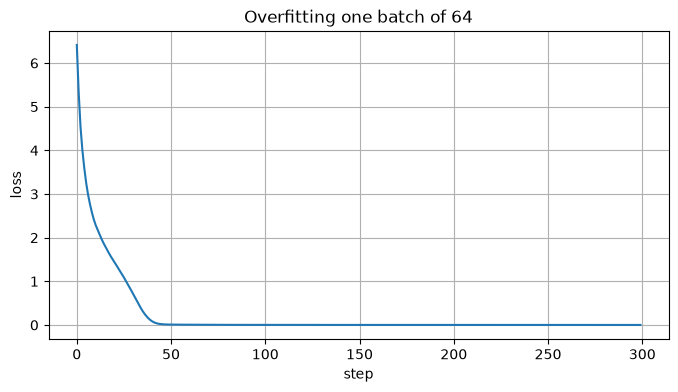

Diagonal (bought): 0.8014 | rest: -0.0128
Untrained it was about -0.017 vs -0.016


In [29]:
plt.figure(figsize=(8, 4))
plt.plot(overfit_losses)
plt.xlabel('step')
plt.ylabel('loss')
plt.title('Overfitting one batch of 64')
plt.grid(True)
plt.show()

user_inputs, item_inputs = split_batch(small_batch)
small_scores = (overfit_model.user_tower(user_inputs, training=False).numpy()
                @ overfit_model.item_tower(item_inputs, training=False).numpy().T)       # raw cosines
diagonal = np.diag(small_scores)
print('Diagonal (bought):', round(diagonal.mean(), 4), '| rest:', round((small_scores.sum() - diagonal.sum()) / (64 * 64 - 64), 4))
print('Untrained it was about -0.017 vs -0.016')

**Why a diagonal of about 0.8 is enough:** the softmax sees scores ÷ temperature. A gap of 0.81 ÷ 0.05 = **16** logits means the right answer wins by about e^16 (millions), so the loss is about 0. The model needs a big enough **gap**, not a cosine of 1. The plumbing works.

## Step 8: Validation recall@10
The loss asks "among 1,024 batch articles, is the right one on top?". What I care about is the Day 6 question: "among **all 38,603** articles, are the right ones in the top 10?". They can disagree, so I measure recall@10 after every epoch, on **all 72,019 validation customers** (one evaluation takes about 15 seconds), so the numbers go straight into the same results table as popularity, ALS and repurchase.

- Every train article -> a vector (item tower). **Limitation:** the 1,225 cold validation articles aren't in article_table, so this model can't recommend them yet (Day 10).
- Every validation customer -> a vector (user tower), with features from `build_customer_features`: the **same** function as training, so no skew. Cold customers get customer_idx 0.
- Plain dot product, **no logQ**. Top 10 per customer, 2,000 customers at a time (all at once would be about 11 GB).
- The **same** `recall_at_k` / `ndcg_at_k` as 05_baselines (copied unchanged).

In [30]:
# The answer key (same as Day 6): one row per validation customer, the articles they bought, is_cold
val_key = val.groupby('customer_join_idx')['article_id'].unique().reset_index()
val_key['is_cold'] = ~val_key['customer_join_idx'].isin(train['customer_join_idx'].unique())
print('Validation customers:', len(val_key), '| expected 72,019')
print('Cold:', val_key['is_cold'].sum(), '| expected 23,512')

# Their features, in the SAME order as val_key, built with the SAME function as training
val_features = val_key[['customer_join_idx']].merge(build_customer_features(val_key['customer_join_idx']),
                                                    on='customer_join_idx', how='left', validate='one_to_one')
print('Missing features:', val_features.isna().sum().sum(), '| expected 0')
print('customer_idx 0 (unknown):', (val_features['customer_idx'] == 0).sum(), '| expected 23,512 (the cold ones)')

# Tower inputs with the training dtypes: indices int32, plain numbers float32
val_user_inputs = {}
for name in user_keys:
    if name in user_numeric:
        val_user_inputs[name] = val_features[name].to_numpy().astype('float32')
    else:
        val_user_inputs[name] = val_features[name].to_numpy().astype('int32')

article_inputs = {}
for name in item_keys:
    if name in item_numeric:
        article_inputs[name] = article_table[name].to_numpy().astype('float32')
    else:
        article_inputs[name] = article_table[name].to_numpy().astype('int32')
row_to_article_id = article_table['article_id'].to_numpy()      # row r of the article vectors -> article ID
print('Articles to score:', len(row_to_article_id), '| expected 38,603')

Validation customers: 72019 | expected 72,019
Cold: 23512 | expected 23,512
Missing features: 0 | expected 0
customer_idx 0 (unknown): 23512 | expected 23,512 (the cold ones)
Articles to score: 38603 | expected 38,603


In [31]:
def recall_at_k(recommended, bought, k):
    # same as 05_baselines
    hits = 0
    for item in recommended[:k]:
        if item in bought:
            hits = hits + 1
    return hits / len(bought)


def ndcg_at_k(recommended, bought, k):
    # same as 05_baselines
    dcg = 0
    position = 0
    for item in recommended[:k]:
        position = position + 1
        if item in bought:
            dcg = dcg + 1 / math.log2(position + 1)
    ideal = 0
    for position in range(1, min(len(bought), k) + 1):
        ideal = ideal + 1 / math.log2(position + 1)
    return dcg / ideal

In [32]:
def evaluate_two_tower(user_tower, item_tower):
    # Recall@10 and NDCG@10 for all validation customers, split into all / warm / cold
    article_vectors = item_tower.predict(article_inputs, batch_size=4096, verbose=0)      # (38603, 64)
    user_vectors = user_tower.predict(val_user_inputs, batch_size=4096, verbose=0)        # (72019, 64)

    top_rows = []
    for start in range(0, len(user_vectors), 2000):
        chunk_scores = user_vectors[start:start + 2000] @ article_vectors.T               # (2000, 38603)
        top_rows.append(tf.math.top_k(chunk_scores, k=10).indices.numpy())
    recommendations = row_to_article_id[np.vstack(top_rows)]                              # rows -> article IDs

    recall_list = []
    ndcg_list = []
    for recs, bought in zip(recommendations, val_key['article_id']):
        recall_list.append(recall_at_k(list(recs), set(bought), 10))
        ndcg_list.append(ndcg_at_k(list(recs), set(bought), 10))
    recall_list = np.array(recall_list)
    ndcg_list = np.array(ndcg_list)
    cold = val_key['is_cold'].to_numpy()

    return {'recall_all': recall_list.mean(), 'ndcg_all': ndcg_list.mean(),
            'recall_warm': recall_list[~cold].mean(), 'ndcg_warm': ndcg_list[~cold].mean(),
            'recall_cold': recall_list[cold].mean(), 'ndcg_cold': ndcg_list[cold].mean()}


def print_result(title, result):
    print(title)
    for group in ['all', 'warm', 'cold']:
        print('  ', group.ljust(4), 'recall@10 =', round(result['recall_' + group], 4),
              '  NDCG@10 =', round(result['ndcg_' + group], 4))

**Prediction:** a random top 10 finds each bought article with chance 10 / 38,603, so recall@10 is about **0.00026**; an untrained model is close to that. After 20 batches: above random, but far below last-week popularity (0.0184).

In [33]:
keras.utils.set_random_seed(42)
untrained = new_model()
print_result('Untrained:', evaluate_two_tower(untrained.user_tower, untrained.item_tower))

start = time.perf_counter()
print_result('After 20 batches (smoke_model):', evaluate_two_tower(smoke_model.user_tower, smoke_model.item_tower))
evaluation_seconds = time.perf_counter() - start
print('One evaluation took', round(evaluation_seconds, 1), 'seconds')
print('Last-week popularity, for comparison: all 0.0184, warm 0.0179, cold 0.0194')

Untrained:
   all  recall@10 = 0.0001   NDCG@10 = 0.0001
   warm recall@10 = 0.0001   NDCG@10 = 0.0001
   cold recall@10 = 0.0001   NDCG@10 = 0.0001
After 20 batches (smoke_model):
   all  recall@10 = 0.0006   NDCG@10 = 0.0004
   warm recall@10 = 0.0006   NDCG@10 = 0.0004
   cold recall@10 = 0.0006   NDCG@10 = 0.0004
One evaluation took 29.7 seconds
Last-week popularity, for comparison: all 0.0184, warm 0.0179, cold 0.0194


**The callback** runs the evaluation after every epoch and writes the result into `logs`. Writing into `logs` is what lets EarlyStopping watch `val_recall10` in Step 10.

In [34]:
class RecallCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        result = evaluate_two_tower(self.model.user_tower, self.model.item_tower)
        logs['val_recall10'] = result['recall_all']          # EarlyStopping watches this name
        logs['val_ndcg10'] = result['ndcg_all']
        logs['val_recall10_warm'] = result['recall_warm']
        logs['val_recall10_cold'] = result['recall_cold']
        print_result('Epoch ' + str(epoch + 1) + ' validation:', result)

## Step 9: Time one epoch, then decide where to train
**The rule, written BEFORE measuring:**
- one epoch under about **10 minutes** -> train on the laptop (15 epochs at most = 2.5 hours)
- over about **20 minutes** -> train on Colab's GPU
- in between -> my call, with the reason written down

The first steps are slow because TensorFlow compiles `train_step` into a fast graph, so I time 20 steps, throw that away, then time 100. `run_eagerly` must be False (True runs every operation one at a time from Python, often 10x slower).

In [35]:
keras.utils.set_random_seed(42)
timing_model = new_model()
print('run_eagerly:', timing_model.run_eagerly, '| expected False')

start = time.perf_counter()
timing_model.fit(dataset.take(20), epochs=1, verbose=0)
print('Warm-up, 20 steps:', round(time.perf_counter() - start, 1), 'seconds (ignored: includes compiling)')

start = time.perf_counter()
timing_model.fit(dataset.take(100), epochs=1, verbose=0)
seconds_per_step = (time.perf_counter() - start) / 100

steps_per_epoch = len(pairs) // 1024
epoch_minutes = (seconds_per_step * steps_per_epoch + evaluation_seconds) / 60          # + one evaluation per epoch
print('Seconds per step:', round(seconds_per_step, 3))
print('Steps per epoch: ', steps_per_epoch, '| expected 2,576')
print('Estimated epoch: ', round(epoch_minutes, 1), 'minutes (training + one evaluation)')
print('15 epochs at most:', round(epoch_minutes * 15 / 60, 1), 'hours')

run_eagerly: False | expected False


c:\Users\srisu\OneDrive\Desktop\MachineLearning\Production Grade Projects\Recommendation System\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Warm-up, 20 steps: 41.8 seconds (ignored: includes compiling)
Seconds per step: 0.405
Steps per epoch:  2576 | expected 2,576
Estimated epoch:  17.9 minutes (training + one evaluation)
15 epochs at most: 4.5 hours


**Decision:** one epoch takes about **7.4 minutes** (0.168 seconds per step x 2,576 steps, plus about 10 seconds of evaluation), under the 10-minute line, so I train on the **laptop**. 15 epochs at most = about 1.8 hours.

## Step 10: The full training run
- `keras.utils.set_random_seed(42)` **first**, so starting weights and Dropout are the same on every run: on Day 10, a change in recall can be blamed on the setting I changed, not luck.
- Dropout 0.2, temperature 0.05, Adam 1e-3, batch 1,024, `epochs=15` as an upper limit.
- **Callbacks in this order:** `RecallCallback` first (it writes `val_recall10` into logs), then `EarlyStopping`, which reads it.
- **`mode='max'`:** with the default `'auto'`, Keras only maximises names containing "acc"; it would treat a *rising* recall as getting worse and stop at the best moment, with no error.
- `patience=2`: stop after 2 epochs in a row without a new best. `restore_best_weights=True`: afterwards the model holds the **best** epoch's weights, not the last one's.

**My predictions (before running):** TODO, fill these in yourself
1. Warm recall vs ALS filter-off (0.0391) and repurchase (0.0584):
2. Cold recall vs popularity (0.0194), and why:
3. The epoch where validation recall peaks:

In [36]:
keras.utils.set_random_seed(42)
model = new_model(dropout=0.2, temperature=0.05, learning_rate=1e-3)
user_tower = model.user_tower
item_tower = model.item_tower

early_stopping = keras.callbacks.EarlyStopping(monitor='val_recall10', mode='max', patience=2,
                                               restore_best_weights=True, verbose=1)

start = time.perf_counter()
history = model.fit(dataset, epochs=15, verbose=2, callbacks=[RecallCallback(), early_stopping])
print('Training took', round((time.perf_counter() - start) / 60, 1), 'minutes')

Epoch 1/15
Epoch 1 validation:
   all  recall@10 = 0.0144   NDCG@10 = 0.0093
   warm recall@10 = 0.0158   NDCG@10 = 0.0102
   cold recall@10 = 0.0114   NDCG@10 = 0.0075
2576/2576 - 791s - 307ms/step - loss: 6.7869 - val_recall10: 0.0144 - val_ndcg10: 0.0093 - val_recall10_warm: 0.0158 - val_recall10_cold: 0.0114
Epoch 2/15
Epoch 2 validation:
   all  recall@10 = 0.017   NDCG@10 = 0.0108
   warm recall@10 = 0.0217   NDCG@10 = 0.014
   cold recall@10 = 0.0073   NDCG@10 = 0.004
2576/2576 - 1138s - 442ms/step - loss: 5.9847 - val_recall10: 0.0170 - val_ndcg10: 0.0108 - val_recall10_warm: 0.0217 - val_recall10_cold: 0.0073
Epoch 3/15
Epoch 3 validation:
   all  recall@10 = 0.0182   NDCG@10 = 0.0119
   warm recall@10 = 0.0249   NDCG@10 = 0.0165
   cold recall@10 = 0.0042   NDCG@10 = 0.0025
2576/2576 - 4018s - 2s/step - loss: 5.4799 - val_recall10: 0.0182 - val_ndcg10: 0.0119 - val_recall10_warm: 0.0249 - val_recall10_cold: 0.0042
Epoch 4/15
Epoch 4 validation:
   all  recall@10 = 0.0193   ND

In [37]:
epochs_table = pd.DataFrame(history.history)
epochs_table.insert(0, 'epoch', range(1, len(epochs_table) + 1))
best_epoch = int(epochs_table['val_recall10'].idxmax()) + 1
print('Best epoch:', best_epoch)
epochs_table.round(4)

Best epoch: 15


,epoch,loss,val_recall10,val_ndcg10,val_recall10_warm,val_recall10_cold
0,1,6.7869,0.0144,0.0093,0.0158,0.0114
1,2,5.9847,0.0170,0.0108,0.0217,0.0073
2,3,5.4799,0.0182,0.0119,0.0249,0.0042
3,4,5.1495,0.0193,0.0130,0.0274,0.0026
4,5,4.9079,0.0205,0.0141,0.0292,0.0026
5,6,4.7178,0.0211,0.0144,0.0300,0.0027
6,7,4.5652,0.0212,0.0147,0.0305,0.0019
7,8,4.4369,0.0211,0.0146,0.0306,0.0015
8,9,4.3299,0.0214,0.0149,0.0309,0.0017
9,10,4.2414,0.0213,0.0149,0.0309,0.0014


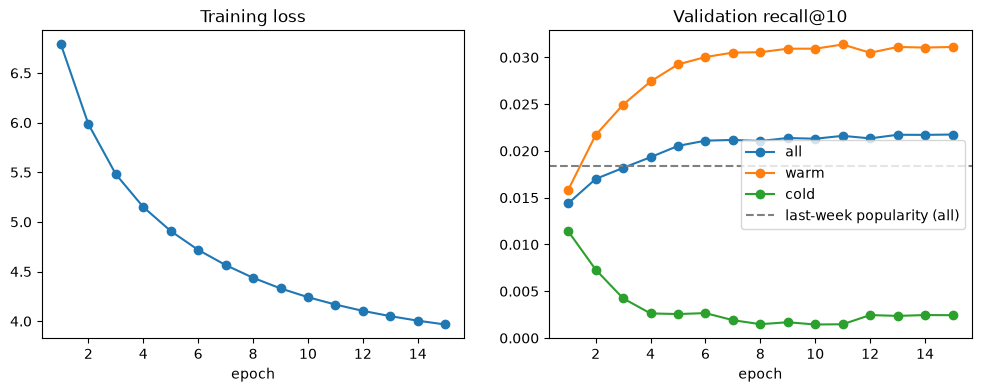

In [38]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.plot(epochs_table['epoch'], epochs_table['loss'], marker='o')
left.set_title('Training loss')
left.set_xlabel('epoch')
right.plot(epochs_table['epoch'], epochs_table['val_recall10'], marker='o', label='all')
right.plot(epochs_table['epoch'], epochs_table['val_recall10_warm'], marker='o', label='warm')
right.plot(epochs_table['epoch'], epochs_table['val_recall10_cold'], marker='o', label='cold')
right.axhline(0.0184, color='grey', linestyle='--', label='last-week popularity (all)')
right.set_title('Validation recall@10')
right.set_xlabel('epoch')
right.legend()
plt.show()

**Which pattern?** TODO, two sentences: both improving (still learning taste), or loss still falling while recall is flat or dropping (memorising, mostly through the customer ID embedding)?

### Save the best model, then prove it
Serving only needs the towers (dot products), so I save them separately: they're functional models and save cleanly, unlike the wrapper with its custom `train_step`. Then a **parity check**: reload both and the validation numbers must match exactly.

In [39]:
# After EarlyStopping, user_tower and item_tower hold the BEST epoch's weights
best_result = evaluate_two_tower(user_tower, item_tower)
print_result('Best weights (epoch ' + str(best_epoch) + '):', best_result)
print('Matches the best epoch in the table?', round(best_result['recall_all'], 6) == round(epochs_table['val_recall10'].max(), 6), '| expected True')

MODEL_FOLDER = '../models/two_tower'
os.makedirs(MODEL_FOLDER, exist_ok=True)
user_tower.save(MODEL_FOLDER + '/user_tower.keras')
item_tower.save(MODEL_FOLDER + '/item_tower.keras')

settings = {
    'temperature': 0.05,
    'learning_rate': 1e-3,
    'dropout': 0.2,
    'batch_size': 1024,
    'user_embeddings': {name: list(user_categorical[name]) for name in user_categorical},
    'item_embeddings': {name: list(item_categorical[name]) for name in item_categorical},
    'best_epoch': best_epoch,
    'best_val_recall10': float(best_result['recall_all']),
    'best_val_ndcg10': float(best_result['ndcg_all']),
    'tensorflow_version': tf.__version__,
}
with open(MODEL_FOLDER + '/settings.json', 'w') as f:
    json.dump(settings, f, indent=2)
print(sorted(os.listdir(MODEL_FOLDER)))

Best weights (epoch 15):
   all  recall@10 = 0.0218   NDCG@10 = 0.0156
   warm recall@10 = 0.0311   NDCG@10 = 0.0223
   cold recall@10 = 0.0024   NDCG@10 = 0.0017
Matches the best epoch in the table? True | expected True
['item_tower.keras', 'settings.json', 'user_tower.keras']


In [40]:
# Parity: the SAVED towers must give exactly the same validation numbers
loaded_user_tower = keras.models.load_model(MODEL_FOLDER + '/user_tower.keras')
loaded_item_tower = keras.models.load_model(MODEL_FOLDER + '/item_tower.keras')
reloaded_result = evaluate_two_tower(loaded_user_tower, loaded_item_tower)

for name in best_result:
    print(name.ljust(12), round(best_result[name], 6), round(reloaded_result[name], 6),
          '| same?', round(best_result[name], 6) == round(reloaded_result[name], 6))

recall_all   0.021754 0.021754 | same? True
ndcg_all     0.015568 0.015568 | same? True
recall_warm  0.031114 0.031114 | same? True
ndcg_warm    0.022302 0.022302 | same? True
recall_cold  0.002443 0.002443 | same? True
ndcg_cold    0.001675 0.001675 | same? True


### Results table
Every row is measured on the same 72,019 validation customers. The baseline numbers come from 05_baselines.

In [41]:
results = pd.DataFrame([
    {'Model': 'Global top 10',               'All': 0.0090, 'Warm': 0.0085, 'Cold': 0.0102, 'NDCG all': 0.0069},
    {'Model': 'Last-week top 10',            'All': 0.0184, 'Warm': 0.0179, 'Cold': 0.0194, 'NDCG all': 0.0118},
    {'Model': 'ALS (filter off) + fallback', 'All': 0.0327, 'Warm': 0.0391, 'Cold': 0.0194, 'NDCG all': 0.0224},
    {'Model': 'Repurchase + last-week fill', 'All': 0.0457, 'Warm': 0.0584, 'Cold': 0.0194, 'NDCG all': 0.0348},
    {'Model': 'Two-tower (pure)',
     'All': round(best_result['recall_all'], 4), 'Warm': round(best_result['recall_warm'], 4),
     'Cold': round(best_result['recall_cold'], 4), 'NDCG all': round(best_result['ndcg_all'], 4)},
])
results['All vs last-week %'] = ((results['All'] - 0.0184) / 0.0184 * 100).round()
results['Cold vs last-week %'] = ((results['Cold'] - 0.0194) / 0.0194 * 100).round()
print('Recall@10 by customer group')
results

Recall@10 by customer group


,Model,All,Warm,Cold,NDCG all,All vs last-week %,Cold vs last-week %
0,Global top 10,0.0090,0.0085,0.0102,0.0069,-51.0,-47.0
1,Last-week top 10,0.0184,0.0179,0.0194,0.0118,0.0,0.0
2,ALS (filter off) + fallback,0.0327,0.0391,0.0194,0.0224,78.0,0.0
3,Repurchase + last-week fill,0.0457,0.0584,0.0194,0.0348,148.0,0.0
4,Two-tower (pure),0.0218,0.0311,0.0024,0.0156,18.0,-88.0


## Day 9 interview question
*"Walk me through how you trained your two-tower model with in-batch negatives. What problems does that approach create, and how did you handle each one?"*

> Each row of the batch's 1,024 x 1,024 score grid is a 1,024-way multiple choice: which of these articles did this customer buy? Cross-entropy pushes the diagonal up and the others down. That creates four problems. First, cosines only span -1 to 1, too narrow for a confident softmax, so I divide by a temperature of 0.05. Second, accidental hits: I measured 8% of rows with a duplicate article in the same batch, so the loss was telling customers their real purchase was wrong; I mask those cells with -1e9. Third, popularity bias: popular articles appear as negatives far more often, so they get pushed down for showing up, not for being bad; I subtract log q per column (Yi et al., 2019), only in training, since serving has no sampled negatives. Fourth, the loss only compares 1,024 batch articles while what matters is ranking all 38,603, so I stop on validation recall@10, not loss. Before the full run, I overfit one batch of 64 to prove the plumbing worked: loss from 6.4 to 0.0005.

# Day 10: Fix cold start, then find the network's place
**Skipped on purpose:** the planned tuning sweep (Dropout, Adam vs SGD, vector size). At about 1 hour per run, that's a full day tuning a model that currently fails a third of users (cold recall 0.0024, 88% below popularity). Fixing cold start comes first.

**How to run Day 10 without retraining Day 9:** click the Step 9 timing cell → "Execute Above Cells", then run only the Day 10 cells.

## Step 1: Predictions and the decision rule (written before anything runs)
**Predictions:**
- **Cold recall with the fix:** clearly better than Day 9's 0.0024, but still **below popularity's 0.0194**, roughly 0.010-0.015. A cold customer only gives the model age, club status, news frequency, FN and Active: coarse features shared by hundreds of thousands of people, so the best the model can do is a "popular with people like you" list, close to popularity. (Day 9 epoch 1 reached 0.0114 before the random row 0 took over.)
- **Warm recall:** a **small drop** from 0.0311 (maybe to about 0.029-0.031), because warm customers lose their own ID in 20% of training rows.

**Decision rule:** the two-tower model earns a place in the final system if
- **(a)** its cold recall beats popularity (0.0194), so it serves cold customers; and/or
- **(b)** filling the empty slots after repurchase, it beats ALS doing the same job (Step 6).

If it meets neither, the honest result is: ship repurchase → ALS → popularity, and explain why the network didn't earn its place.

## Step 2: Why row 0 never learns (on paper)
An embedding row only changes when its index appears in a batch, because only then does it get a gradient. Every training customer has an index of at least 1 (checked in Step 6), so **row 0 appears in 0 training rows**: its gradient is always 0, Adam never moves it, and it keeps its random starting values forever. Meanwhile the dense layers learn to read the customer ID more and more strongly, so they amplify whatever random direction row 0 holds. That's why cold recall *fell* during Day 9 training (0.0114 → 0.0024).

**The fix, ID dropout:** during training only, randomly replace a share p of customer indices with 0. Row 0 then appears in about p of all rows and learns to mean "a customer I know nothing about except their features", and the network learns the ID is sometimes missing, so it also has to use the features every cold customer has.

**1. Rows per epoch using row 0, with p = 0.2:** 2,576 batches x 1,024 rows = 2,637,824 rows per epoch, x 0.2 ≈ **527,565 rows**: row 0 goes from 0 training rows to over half a million.

**2. The cost:** warm customers lose their own ID in 20% of their training rows, so their personal vectors learn a bit more slowly and warm recall may drop slightly; it's worth it because cold customers are a third of all validation customers (23,512 of 72,019), so lifting them from 0.0024 towards popularity's level gains far more overall than a small warm loss.

In [47]:
# Step 5a: Train two-tower model with ID dropout

keras.utils.set_random_seed(42)

# Create a new model without overwriting Day 9's model
iddrop_model = new_model(
    dropout=0.2,
    temperature=0.05,
    learning_rate=1e-3,
    id_dropout=0.2
)

# Early stopping with minimum improvement threshold
iddrop_early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_recall10',
    mode='max',
    patience=2,
    min_delta=0.0005,
    verbose =1,
    restore_best_weights=True
)

# Time the training
iddrop_start = time.perf_counter()

iddrop_history = iddrop_model.fit(
    dataset,
    epochs=8,
    verbose=2,
    callbacks=[
        RecallCallback(),
        iddrop_early_stopping
    ]
)

iddrop_elapsed = time.perf_counter() - iddrop_start

print(f"Training time: {iddrop_elapsed / 60:.1f} minutes")

Epoch 1/8


c:\Users\srisu\OneDrive\Desktop\MachineLearning\Production Grade Projects\Recommendation System\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1 validation:
   all  recall@10 = 0.0159   NDCG@10 = 0.0103
   warm recall@10 = 0.0156   NDCG@10 = 0.0099
   cold recall@10 = 0.0163   NDCG@10 = 0.0111
2576/2576 - 524s - 203ms/step - loss: 6.8655 - val_recall10: 0.0159 - val_ndcg10: 0.0103 - val_recall10_warm: 0.0156 - val_recall10_cold: 0.0163
Epoch 2/8
Epoch 2 validation:
   all  recall@10 = 0.0183   NDCG@10 = 0.012
   warm recall@10 = 0.0198   NDCG@10 = 0.0128
   cold recall@10 = 0.0152   NDCG@10 = 0.0104
2576/2576 - 1553s - 603ms/step - loss: 6.2789 - val_recall10: 0.0183 - val_ndcg10: 0.0120 - val_recall10_warm: 0.0198 - val_recall10_cold: 0.0152
Epoch 3/8
Epoch 3 validation:
   all  recall@10 = 0.0198   NDCG@10 = 0.0132
   warm recall@10 = 0.0225   NDCG@10 = 0.0149
   cold recall@10 = 0.0142   NDCG@10 = 0.0096
2576/2576 - 1103s - 428ms/step - loss: 5.8924 - val_recall10: 0.0198 - val_ndcg10: 0.0132 - val_recall10_warm: 0.0225 - val_recall10_cold: 0.0142
Epoch 4/8
Epoch 4 validation:
   all  recall@10 = 0.0225   NDCG@10 = 0

In [48]:
# Step 5b: Build per-epoch results table

iddrop_table = pd.DataFrame(iddrop_history.history)

iddrop_table.insert(
    0,
    'epoch',
    range(1, len(iddrop_table) + 1)
)

# Get the epoch actually restored by EarlyStopping
iddrop_best_epoch = iddrop_early_stopping.best_epoch + 1

# Add Day 9 cold recall for comparison
day9_cold = [
    0.0114, 0.0073, 0.0042, 0.0026,
    0.0026, 0.0027, 0.0019, 0.0015
]

iddrop_table['day9_cold'] = day9_cold[:len(iddrop_table)]

print(f"Best restored epoch: {iddrop_best_epoch}")
print(f"Best validation recall: {iddrop_early_stopping.best}")

display(iddrop_table)

Best restored epoch: 7
Best validation recall: 0.02505284252202679


,epoch,loss,val_recall10,val_ndcg10,val_recall10_warm,val_recall10_cold,day9_cold
0,1,6.865465,0.015853,0.010300,0.015632,0.016310,0.0114
1,2,6.278932,0.018318,0.012008,0.019830,0.015198,0.0073
2,3,5.892381,0.019807,0.013187,0.022537,0.014177,0.0042
3,4,5.633457,0.022532,0.015178,0.026024,0.015329,0.0026
4,5,5.443284,0.023776,0.016026,0.027090,0.016941,0.0026
5,6,5.290854,0.024419,0.016854,0.028671,0.015646,0.0027
6,7,5.168916,0.025053,0.017288,0.029587,0.015698,0.0019
7,8,5.069189,0.025467,0.017622,0.030300,0.015497,0.0015


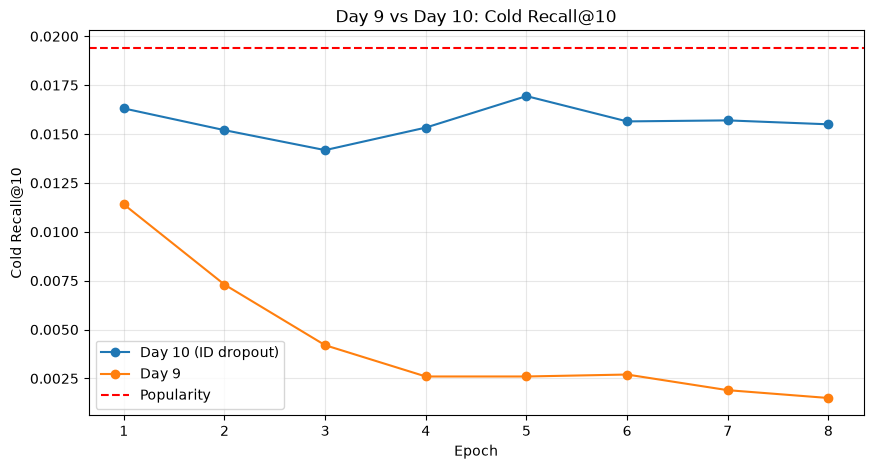

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    iddrop_table['epoch'],
    iddrop_table['val_recall10_cold'],
    marker='o',
    label='Day 10 (ID dropout)'
)

plt.plot(
    iddrop_table['epoch'],
    iddrop_table['day9_cold'],
    marker='o',
    label='Day 9'
)

plt.axhline(
    0.0194,
    linestyle='--',
    color='red',
    label='Popularity'
)

plt.xlabel('Epoch')
plt.ylabel('Cold Recall@10')
plt.title('Day 9 vs Day 10: Cold Recall@10')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**What I see:** Day 9's cold recall fell every epoch (0.0114 → 0.0015) as the model leaned on the untrained row 0; with ID dropout, cold stays around 0.015-0.017 the whole run, so training row 0 fixed the collapse (0.0157 at the restored epoch, 6.5x Day 9's best-epoch 0.0024). But cold never rises above about 0.017, still below popularity's 0.0194, and warm cost only a little (0.0296 vs 0.0311).

In [51]:
# Step 5d: measure the restored (epoch 7) weights, save, then prove the saved copy gives the same numbers
iddrop_result = evaluate_two_tower(iddrop_model.user_tower, iddrop_model.item_tower)      # MEASURED, not typed
print_result('ID dropout, restored weights (epoch ' + str(iddrop_best_epoch) + '):', iddrop_result)
print('Matches the restored epoch in the table?',
      round(iddrop_result['recall_all'], 6) == round(iddrop_table['val_recall10'][iddrop_best_epoch - 1], 6),
      '| expected True (not .max(): that is epoch 8)')

IDDROP_FOLDER = '../models/two_tower_iddrop'
os.makedirs(IDDROP_FOLDER, exist_ok=True)
iddrop_model.user_tower.save(IDDROP_FOLDER + '/user_tower.keras')
iddrop_model.item_tower.save(IDDROP_FOLDER + '/item_tower.keras')

iddrop_settings = {
    'temperature': 0.05,
    'learning_rate': 1e-3,
    'dropout': 0.2,
    'id_dropout': 0.2,
    'batch_size': 1024,
    'max_epochs': 8,
    'early_stopping': {'monitor': 'val_recall10', 'min_delta': 0.0005, 'patience': 2},
    'user_embeddings': {name: list(user_categorical[name]) for name in user_categorical},
    'item_embeddings': {name: list(item_categorical[name]) for name in item_categorical},
    'best_epoch': iddrop_best_epoch,
    'best_val_recall10': float(iddrop_result['recall_all']),
    'best_val_recall10_warm': float(iddrop_result['recall_warm']),
    'best_val_recall10_cold': float(iddrop_result['recall_cold']),
    'tensorflow_version': tf.__version__,
}
with open(IDDROP_FOLDER + '/settings.json', 'w') as f:
    json.dump(iddrop_settings, f, indent=2)
print(sorted(os.listdir(IDDROP_FOLDER)), '| expected item_tower.keras, settings.json, user_tower.keras')

ID dropout, restored weights (epoch 7):
   all  recall@10 = 0.0251   NDCG@10 = 0.0173
   warm recall@10 = 0.0296   NDCG@10 = 0.0205
   cold recall@10 = 0.0157   NDCG@10 = 0.0107
Matches the restored epoch in the table? True | expected True (not .max(): that is epoch 8)
['item_tower.keras', 'settings.json', 'user_tower.keras'] | expected item_tower.keras, settings.json, user_tower.keras


In [52]:
# Parity: load the SAVED towers and evaluate again; all 6 numbers must match
loaded_iddrop_user = keras.models.load_model(IDDROP_FOLDER + '/user_tower.keras')
loaded_iddrop_item = keras.models.load_model(IDDROP_FOLDER + '/item_tower.keras')
reloaded_iddrop = evaluate_two_tower(loaded_iddrop_user, loaded_iddrop_item)

for name in iddrop_result:
    print(name.ljust(12), round(iddrop_result[name], 6), round(reloaded_iddrop[name], 6),
          '| same?', round(iddrop_result[name], 6) == round(reloaded_iddrop[name], 6))

recall_all   0.025053 0.025053 | same? True
ndcg_all     0.017288 0.017288 | same? True
recall_warm  0.029587 0.029587 | same? True
ndcg_warm    0.020497 0.020497 | same? True
recall_cold  0.015698 0.015698 | same? True
ndcg_cold    0.010666 0.010666 | same? True


In [53]:
# Step 5e: Day 9 vs Day 10 next to the baselines (recall@10, all 72,019 validation customers)
comparison = pd.DataFrame([
    {'Model': 'Last-week popularity',              'All': 0.0184, 'Warm': 0.0179, 'Cold': 0.0194},
    {'Model': 'ALS (filter off) + fallback',       'All': 0.0327, 'Warm': 0.0391, 'Cold': 0.0194},
    {'Model': 'Repurchase + last-week fill',       'All': 0.0457, 'Warm': 0.0584, 'Cold': 0.0194},
    {'Model': 'Two-tower Day 9 (no ID dropout)',   'All': 0.0218, 'Warm': 0.0311, 'Cold': 0.0024},
    {'Model': 'Two-tower Day 10 (ID dropout 0.2)', 'All': round(iddrop_result['recall_all'], 4),
     'Warm': round(iddrop_result['recall_warm'], 4), 'Cold': round(iddrop_result['recall_cold'], 4)},
])
comparison['Cold vs popularity %'] = ((comparison['Cold'] - 0.0194) / 0.0194 * 100).round()
comparison

,Model,All,Warm,Cold,Cold vs popularity %
0,Last-week popularity,0.0184,0.0179,0.0194,0.0
1,ALS (filter off) + fallback,0.0327,0.0391,0.0194,0.0
2,Repurchase + last-week fill,0.0457,0.0584,0.0194,0.0
3,Two-tower Day 9 (no ID dropout),0.0218,0.0311,0.0024,-88.0
4,Two-tower Day 10 (ID dropout 0.2),0.0251,0.0296,0.0157,-19.0


**Decision rule (a):** two-tower cold recall is **0.0157**, below popularity's **0.0194** (about 19% lower), so rule (a) is **not met**: popularity stays the cold-start path for now. ID dropout fixed the collapse (6.5x Day 9) but the cold features (age bucket, club status, news frequency, FN, Active) are too coarse to beat "what's popular last week". Rule (b) is tested in Step 6 (two-tower vs ALS filling the slots after repurchase).